In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

COLS = ['age','workclass','fnlwgt','education','education-num','marital-status',
        'occupation','relationship','race','sex','capital-gain','capital-loss',
        'hours-per-week','native-country','income']

df = pd.read_csv('data/adult.data', names=COLS, skipinitialspace=True)
print(df.shape)

(32561, 15)


In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 32561 entries, 0 to 32560
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   age             32561 non-null  int64
 1   workclass       32561 non-null  str  
 2   fnlwgt          32561 non-null  int64
 3   education       32561 non-null  str  
 4   education-num   32561 non-null  int64
 5   marital-status  32561 non-null  str  
 6   occupation      32561 non-null  str  
 7   relationship    32561 non-null  str  
 8   race            32561 non-null  str  
 9   sex             32561 non-null  str  
 10  capital-gain    32561 non-null  int64
 11  capital-loss    32561 non-null  int64
 12  hours-per-week  32561 non-null  int64
 13  native-country  32561 non-null  str  
 14  income          32561 non-null  str  
dtypes: int64(6), str(9)
memory usage: 3.7 MB


In [ ]:
df.info()
print("\n--- Missing values (per column, only where > 0) ---")
missing = df.replace('?', np.nan).isna().sum()
print(missing[missing > 0])

print("\n--- Target distribution ---")
print(df['income'].value_counts())
print("\n--- Target proportion ---")
print(df['income'].value_counts(normalize=True).round(3))

<class 'pandas.DataFrame'>
RangeIndex: 32561 entries, 0 to 32560
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   age             32561 non-null  int64
 1   workclass       32561 non-null  str  
 2   fnlwgt          32561 non-null  int64
 3   education       32561 non-null  str  
 4   education-num   32561 non-null  int64
 5   marital-status  32561 non-null  str  
 6   occupation      32561 non-null  str  
 7   relationship    32561 non-null  str  
 8   race            32561 non-null  str  
 9   sex             32561 non-null  str  
 10  capital-gain    32561 non-null  int64
 11  capital-loss    32561 non-null  int64
 12  hours-per-week  32561 non-null  int64
 13  native-country  32561 non-null  str  
 14  income          32561 non-null  str  
dtypes: int64(6), str(9)
memory usage: 3.7 MB

--- Missing values (per column, only where > 0) ---
workclass         1836
occupation        1843
native-country     583
dty

In [ ]:
df.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
age,32561.0,NaN,NaN,NaN,38.581647,13.640433,17.0,28.0,37.0,48.0,90.0
workclass,32561,9,Private,22696,NaN,NaN,NaN,NaN,NaN,NaN,NaN
fnlwgt,32561.0,NaN,NaN,NaN,189778.366512,105549.977697,12285.0,117827.0,178356.0,237051.0,1484705.0
education,32561,16,HS-grad,10501,NaN,NaN,NaN,NaN,NaN,NaN,NaN
education-num,32561.0,NaN,NaN,NaN,10.080679,2.57272,1.0,9.0,10.0,12.0,16.0
marital-status,32561,7,Married-civ-spouse,14976,NaN,NaN,NaN,NaN,NaN,NaN,NaN
occupation,32561,15,Prof-specialty,4140,NaN,NaN,NaN,NaN,NaN,NaN,NaN
relationship,32561,6,Husband,13193,NaN,NaN,NaN,NaN,NaN,NaN,NaN
race,32561,5,White,27816,NaN,NaN,NaN,NaN,NaN,NaN,NaN
sex,32561,2,Male,21790,NaN,NaN,NaN,NaN,NaN,NaN,NaN


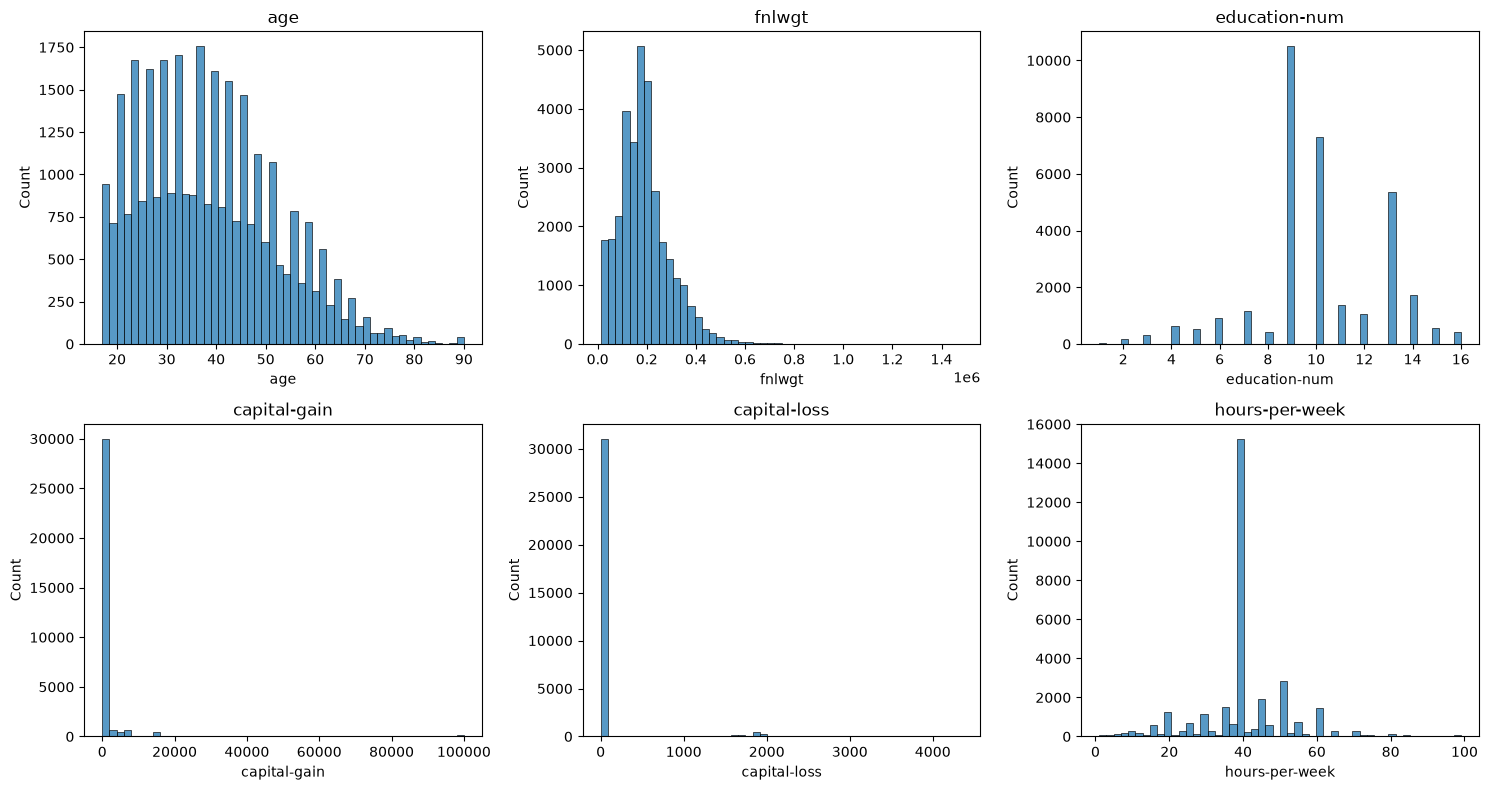

In [ ]:
df_clean = df.replace('?', np.nan)

numeric_cols = ['age', 'fnlwgt', 'education-num',
                'capital-gain', 'capital-loss', 'hours-per-week']

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.flatten(), numeric_cols):
    sns.histplot(df_clean[col], bins=50, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

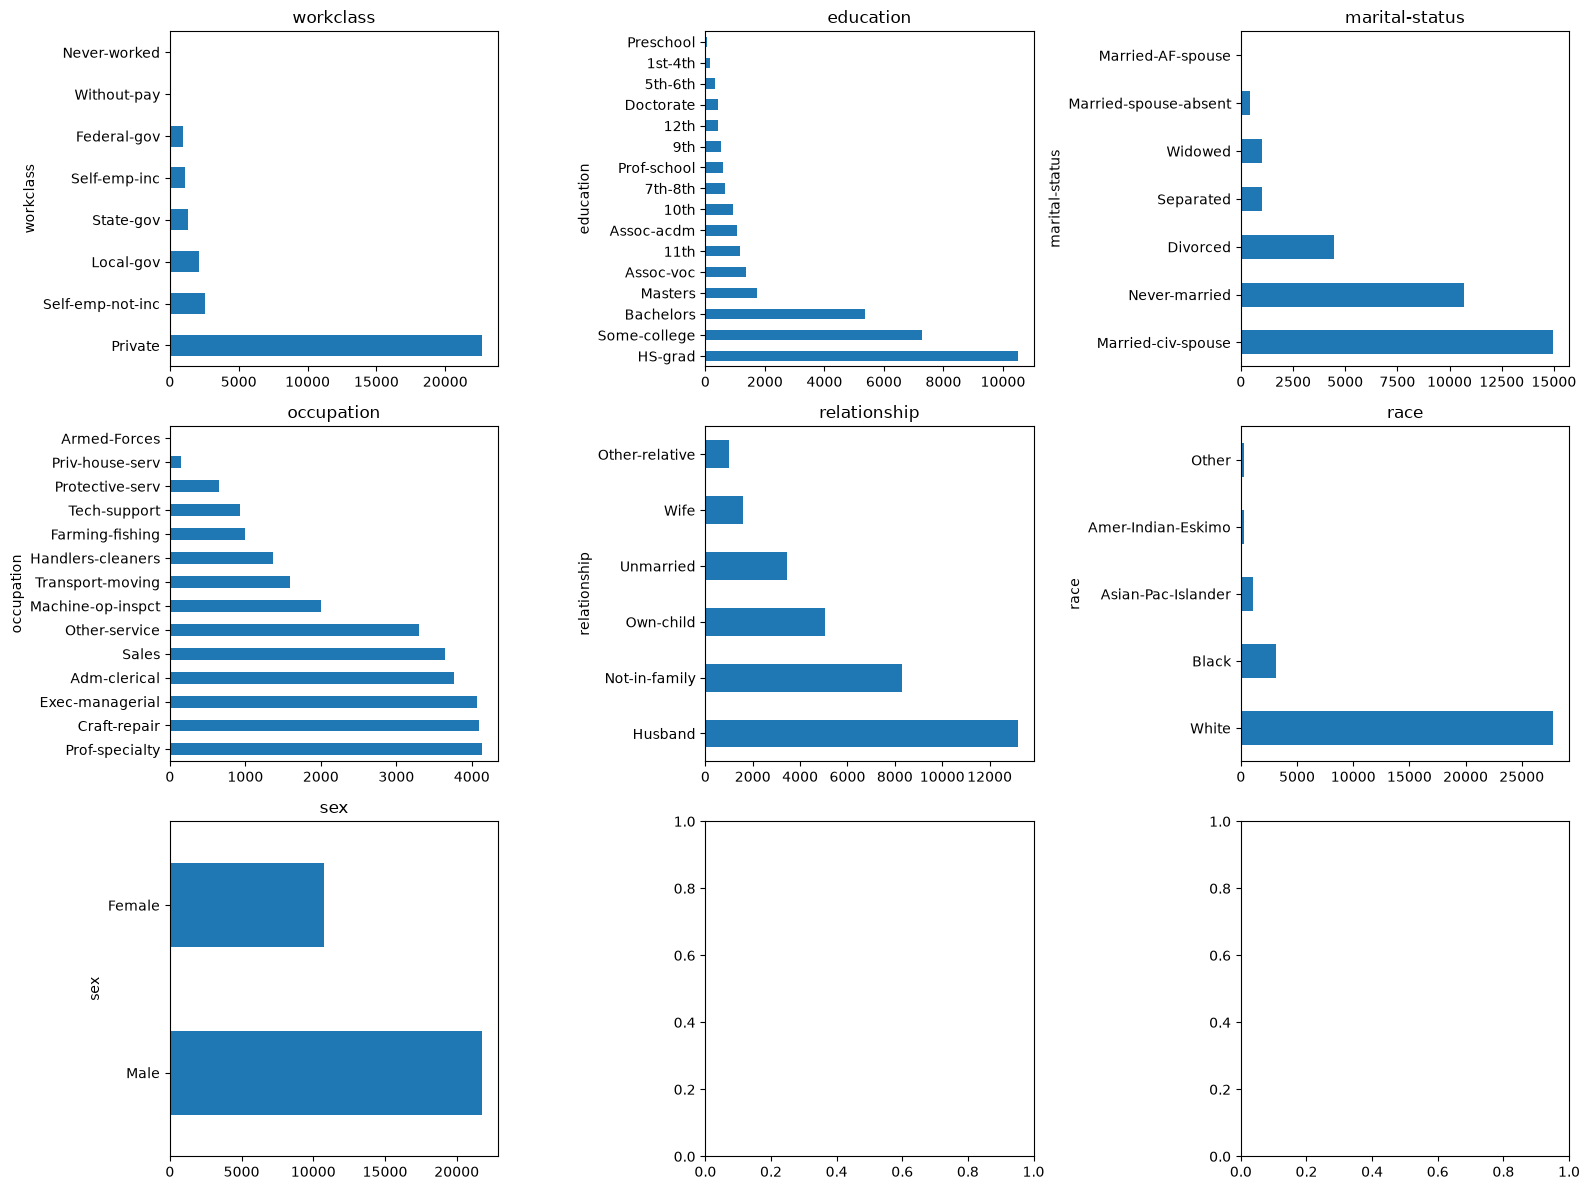

In [ ]:
cat_cols = ['workclass', 'education', 'marital-status',
            'occupation', 'relationship', 'race', 'sex']

fig, axes = plt.subplots(3, 3, figsize=(16, 12))
for ax, col in zip(axes.flatten(), cat_cols):
    df_clean[col].value_counts().plot(kind='barh', ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

Income rate by sex:
sex
Female    0.109
Male      0.306
Name: income_binary, dtype: float64

Income rate by marital-status:
marital-status
Divorced                 0.104
Married-AF-spouse        0.435
Married-civ-spouse       0.447
Married-spouse-absent    0.081
Never-married            0.046
Separated                0.064
Widowed                  0.086
Name: income_binary, dtype: float64

Income rate by education-num:
education-num
1     0.000
2     0.036
3     0.048
4     0.062
5     0.053
6     0.066
7     0.051
8     0.076
9     0.160
10    0.190
11    0.261
12    0.248
13    0.415
14    0.557
15    0.734
16    0.741
Name: income_binary, dtype: float64


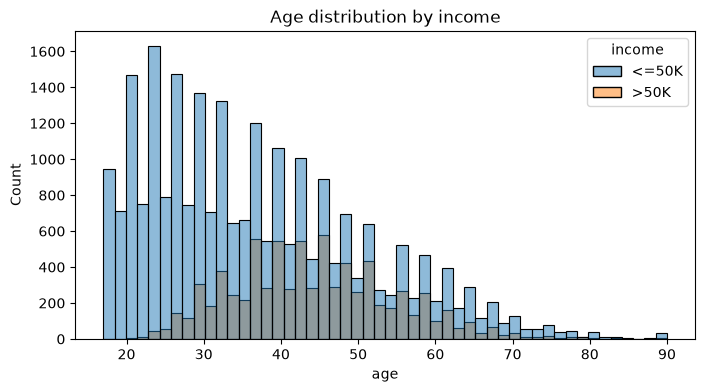

In [ ]:
df_clean['income_binary'] = (df_clean['income'] == '>50K').astype(int)

print("Income rate by sex:")
print(df_clean.groupby('sex')['income_binary'].mean().round(3))

print("\nIncome rate by marital-status:")
print(df_clean.groupby('marital-status')['income_binary'].mean().round(3))

print("\nIncome rate by education-num:")
print(df_clean.groupby('education-num')['income_binary'].mean().round(3))

plt.figure(figsize=(8, 4))
sns.histplot(data=df_clean, x='age', hue='income',
             bins=50, common_norm=False)
plt.title('Age distribution by income')
plt.show()

In [ ]:
from sklearn.model_selection import train_test_split

# Prepare X and y
df_clean['income_binary'] = (df_clean['income'] == '>50K').astype(int)

# Drop 'fnlwgt', 'education', and the original string 'income'
X = df_clean.drop(columns=['fnlwgt', 'education', 'income', 'income_binary'])
y = df_clean['income_binary']

# Split: 80% train, 20% test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Train shape: {X_train.shape}")
print(f"Test shape: {X_test.shape}")

Train shape: (26048, 12)
Test shape: (6513, 12)


In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Separate features by type
num_features = ['age', 'education-num', 'capital-gain', 'capital-loss', 'hours-per-week']
cat_features = ['workclass', 'marital-status', 'occupation', 'relationship', 'race', 'sex', 'native-country']

# Numeric transformer: Fill missing with median, then scale
num_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Categorical transformer: Fill missing with most frequent, then one-hot encode
cat_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

# Combine into a ColumnTransformer
preprocessor = ColumnTransformer(
    transformers=[
        ('num', num_transformer, num_features),
        ('cat', cat_transformer, cat_features)
    ]
)

In [15]:
from sklearn.linear_model import LogisticRegression

lr_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(max_iter=1000, random_state=42))
])

# Train the model
lr_pipeline.fit(X_train, y_train)

# Evaluate on train and test
train_acc = lr_pipeline.score(X_train, y_train)
test_acc = lr_pipeline.score(X_test, y_test)

print(f"Logistic Regression — Train Accuracy: {train_acc:.4f}")
print(f"Logistic Regression — Test Accuracy: {test_acc:.4f}")

Logistic Regression — Train Accuracy: 0.8517
Logistic Regression — Test Accuracy: 0.8551


In [ ]:
# Test accuracy is slightly greater than train accuracy, this means 0 overfitting.

In [16]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

def evaluate_model(model, X_train, y_train, X_test, y_test, name):
    model.fit(X_train, y_train)
    
    y_train_pred = model.predict(X_train)
    y_test_pred = model.predict(X_test)
    
    y_test_proba = model.predict_proba(X_test)[:, 1]
    
    print(f"--- {name} ---")
    print(f"Train Accuracy: {accuracy_score(y_train, y_train_pred):.4f}")
    print(f"Test Accuracy:  {accuracy_score(y_test, y_test_pred):.4f}")
    print(f"Test Precision: {precision_score(y_test, y_test_pred):.4f}")
    print(f"Test Recall:    {recall_score(y_test, y_test_pred):.4f}")
    print(f"Test F1-Score:  {f1_score(y_test, y_test_pred):.4f}")
    print(f"Test ROC-AUC:   {roc_auc_score(y_test, y_test_proba):.4f}\n")
    
    return model

In [17]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

dt_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', DecisionTreeClassifier(random_state=42, max_depth=10)) 
 ])
dt_pipeline = evaluate_model(dt_pipeline, X_train, y_train, X_test, y_test, "Decision Tree")

rf_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1))
])
rf_pipeline = evaluate_model(rf_pipeline, X_train, y_train, X_test, y_test, "Random Forest")

lr_pipeline = evaluate_model(lr_pipeline, X_train, y_train, X_test, y_test, "Logistic Regression")

--- Decision Tree ---
Train Accuracy: 0.8712
Test Accuracy:  0.8612
Test Precision: 0.7771
Test Recall:    0.5938
Test F1-Score:  0.6732
Test ROC-AUC:   0.9066

--- Random Forest ---
Train Accuracy: 0.9782
Test Accuracy:  0.8494
Test Precision: 0.7092
Test Recall:    0.6346
Test F1-Score:  0.6698
Test ROC-AUC:   0.8955

--- Logistic Regression ---
Train Accuracy: 0.8517
Test Accuracy:  0.8551
Test Precision: 0.7382
Test Recall:    0.6167
Test F1-Score:  0.6720
Test ROC-AUC:   0.9076



In [19]:
from sklearn.model_selection import GridSearchCV

rf_pipeline_tune = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(random_state=42, n_jobs=-1))
])

param_grid = {
    'classifier__n_estimators': [50, 100],
    'classifier__max_depth': [10, 15, 20],
    'classifier__min_samples_leaf': [5, 10]
}

grid_search = GridSearchCV(
    rf_pipeline_tune, 
    param_grid, 
    cv=3, 
    scoring='roc_auc', 
    n_jobs=-1, 
    verbose=1
)

grid_search.fit(X_train, y_train)

print(f"\nBest parameters: {grid_search.best_params_}")
print(f"Best Cross-Validation ROC-AUC: {grid_search.best_score_:.4f}")

best_rf_pipeline = grid_search.best_estimator_
evaluate_model(best_rf_pipeline, X_train, y_train, X_test, y_test, "Tuned Random Forest")

Fitting 3 folds for each of 12 candidates, totalling 36 fits

Best parameters: {'classifier__max_depth': 20, 'classifier__min_samples_leaf': 5, 'classifier__n_estimators': 100}
Best Cross-Validation ROC-AUC: 0.9149
--- Tuned Random Forest ---
Train Accuracy: 0.8694
Test Accuracy:  0.8675
Test Precision: 0.7990
Test Recall:    0.6008
Test F1-Score:  0.6858
Test ROC-AUC:   0.9193



,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](12,)","['age','workclass','education-num',...,'capital-loss','hours-per-week', 'native-country']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,12
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainde

In [20]:
import joblib

# Save the best pipeline to disk
joblib.dump(best_rf_pipeline, 'model.bin')
print("Model saved successfully as model.bin")

Model saved successfully as model.bin
